# 18 · A threshold that holds on new topics (Phase 4)

**The problem.** A decision threshold chosen on validation essays keeps its promised false-flag rate on the topics it was chosen on, not on new ones: notebook 16b measured the share of human essays flagged on a topic the model had never seen at **0.4% to 5.8%** with a "1%" threshold. Notebook 17b then showed that the same recipe trained with a different seed has a different logit threshold (+4.57, +3.58, −0.13 for a "1%" target at near-identical AUC), so a threshold in logits belongs to one trained model. This notebook (1) puts every model on one scale that survives that, (2) compares four rules for choosing the threshold, **judged on topics they were not set on**, and (3) adds a "cannot tell" band.

**Everything in sections 1–6 below was written, and committed to git, before any score was read for this phase.** The code cells that follow it were not run when it was committed. The held-out prompts (Summer projects, Electoral college) and the held-out generators are not scored here and are used for nothing.

## 1 · The common scale: a val-human tail probability (conformal p-value)

For a trained model with val-human scores $s_1,\dots,s_n$, an essay scoring $x$ gets

$$p(x) = \frac{1 + \#\{i : s_i \ge x\}}{1 + n}$$

(computed separately for each model, or for each leave-one-prompt-out fold model, from *its own* val humans).

- **It is a conformal p-value.** If a new human essay is exchangeable with the val humans, then $P(p \le a) \le a$ for every $a$ (the new essay's rank among $n + 1$ exchangeable scores is uniform). So "flag when $p \le 0.01$" flags at most 1% of such human essays, for any model, with no assumption about the score's shape. The "+1" counts the new essay itself and makes it valid for finite $n$.
- **Why it puts the seeds on one scale.** $p$ uses only the *rank* of a score among that model's own val humans, so it is unchanged by any monotone rescaling of the logits. Two seeds whose 1% thresholds are +4.57 and −0.13 logits both map exactly 1% of val humans to $p \le 0.01$. Averaging or comparing seeds, folds or recipes on the $p$ scale is meaningful; on the logit scale it is not.
- **What it does not give.** The guarantee is about the val distribution. For an essay on a **new topic** the exchangeability is gone, and the false-flag rate at $p \le 0.01$ can be well above 1%. The rules below therefore pick a flag threshold $\tau$ on the $p$ scale (flag when $p \le \tau$) that is tuned to hold on new topics.

## 2 · The score sets

- **The 13 leave-one-prompt-out score sets of variant A** (spelling/typo augmentation, the Phase 3 winner), one seed (42), one fold per ordinary prompt: seven from Phase 3 and six more run afterwards, because the first seven were chosen to include the extremes and are not a representative sample of topics. In each, the fold's model never saw the left-out prompt; its $p$ is computed against the val humans of the *other* 12 prompts.
- **For context only** (not used to choose anything): the same analysis on the 13 folds of the original recipe (`results/16b_lopo`).
- Each topic's essays are every essay (train, val and test, both labels) of that prompt.

## 3 · The four threshold rules (declared before computing)

Let $\tau$ be the flag threshold on the $p$ scale ("flag if $p \le \tau$"), and *target* the false-flag rate we want (1% or 0.5%). For a set of topics used to set the threshold, take each topic's left-out **human** p-values. Per topic $t$, $\tau_t$ is the largest $\tau$ that keeps that topic's false-flag rate at or below the target (the target-quantile of its human p-values, rounded down).

| rule | $\tau$ |
|---|---|
| **(a) pooled val** (what the project did so far) | the target itself ($p \le$ target flags the target share of val humans) |
| **(b) pooled LOPO** | the target-quantile of all the topics' human p-values pooled |
| **(c) worst topic** | $\min_t \tau_t$: the topic that is hardest to keep under the target decides |
| **(d) topic quantile** | the 20th percentile of the $\tau_t$: 80% of topics can be held at the target (less noisy than the maximum) |

## 4 · How the rules are judged: leave-one-topic-out

For each of the 13 topics in turn: set $\tau$ from the other **12** topics' humans (rule (a) needs no topics), then measure on the 13th, which played no part in setting it: the **false-flag rate** (its humans with $p \le \tau$) and **AI caught** (its AI essays with $p \le \tau$). Repeat for all 13. Per rule and target (1% and 0.5%), report:

1. **mean** false-flag rate over the 13 left-out topics,
2. the **worst** topic's false-flag rate,
3. the **share of topics over target** (a topic is over target when its observed false-flag rate is above the target),
4. **mean AI caught** over the 13 topics (equal weight per topic).

**Intervals.** A bootstrap (1,000 resamples, seed 42) that redraws, inside every fold, the val humans (so the $p$-values move), the left-out humans and the left-out AI essays (whole `dup_cluster` groups), then repeats the whole leave-one-topic-out procedure. Not included: variation between training seeds (one seed per fold).

*A note on "over target".* A rule that sets the threshold exactly at the true target would still see about half of its topics slightly above it by chance. The share over target therefore rewards conservative rules; the constraint on AI caught (next section) is what stops that going too far.

## 5 · The pre-declared choice

Decided **at the 1% target** (0.5% is reported alongside; the same rule is then used for both):

1. **Qualifying rules:** those whose *point estimate* of mean AI caught is within **1.0 percentage point** of rule (a)'s (rule (a) qualifies by definition).
2. **Choose the qualifying rule with the smallest share of topics over target**; ties go to the higher mean AI caught.
3. If **no rule other than (a)** qualifies, or the chosen rule is (a), the trade-off table is reported and **you are asked** before anything is carried forward.

## 6 · The "cannot tell" band (edges proposed and justified before computing)

With the chosen rule, the $p$ scale is cut in three zones:

- **flag**: $p \le \tau_{1\%}$ (the rule's threshold at the 1% target),
- **cannot tell**: $\tau_{1\%} < p \le \tau_{5\%}$ (the same rule at a 5% target),
- **not flagged**: $p > \tau_{5\%}$.

*Why these edges.* 1% is the project's operating point and the lower edge of the band keeps its meaning. 5% is the conventional significance level and the loosest target used in notebook 09; beyond it an essay sits in the bulk of the human distribution (an essay in the top 5% of human scores of its own model's val humans is unusual but common enough that accusing it would be unjustified), while the zone between 1% and 5% is exactly where shifted new-topic human essays land (notebook 09: a 5% val threshold flagged 12.5% of unseen-prompt humans). The band's purpose is that such essays are reported as "cannot tell" and nobody is accused on them. The edges are set by the chosen rule, so they move with it, not with the logit scale.

*What is reported* (leave-one-topic-out, with intervals): the share of human and of AI essays in each zone, and **false flags and AI caught outside the band** (the flag zone). *Exploratory sensitivity, not part of the choice:* the edges (0.5%, 5%) and (1%, 10%).

## 7 · An approximation to state plainly: single-seed folds, three-seed ensemble

The leave-one-prompt-out models are **single-seed**; the final system will be an **ensemble of 3 seeds** (Phase 5). The threshold carries over on the $p$ scale like this: the ensemble's score (for example the mean of its seeds' scores after each is put on its own $p$ scale) gets its own $p$ from its own val humans, and the same $\tau$ (a number on the $p$ scale) is applied. **This assumes** that the ensemble's *topic inflation* is the same as a single model's: that human essays on a new topic land in the same low-$p$ tail zone, at the same rates, as for a single model. Averaging seeds usually makes scores less noisy, which would make new-topic humans *less* extreme than for one model (so the threshold would be conservative, not too lax), but this is an assumption and is **not tested here**: the held-out prompts are checked once, at the end of Phase 5, for the final ensemble, threshold and band together.

The final threshold for the 13 topics all together (no topic left out) is computed in section 11 for use in Phase 5.

In [1]:
import os
os.environ['HF_HUB_OFFLINE'] = '1'
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_splits
from src.conformal import load_topics, compare_rules, band_report, set_tau, tail_p, _p_arrays, loto, RULES

SEED, N_BOOT = 42, 1000
pd.set_option('display.width', 230); pd.set_option('display.max_colwidth', 100)
HUMAN, AI, GREEN, GREY = '#2a78d6', '#eb6834', '#2d7d46', '#9a9a94'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e6e3', 'grid.linewidth': 0.6, 'axes.edgecolor': '#9a9a94', 'axes.titleweight': 'bold'})
data = load_splits()
topics_A = load_topics('../results/17_variants/A', range(13), data)
topics_orig = load_topics('../results/16b_lopo', range(13), data)
print('variant A topics:', [t['name'][:18] for t in topics_A])
assert [t['name'] for t in topics_A] == [t['name'] for t in topics_orig]

variant A topics: ['"A Cowboy Who Rode', 'Car-free cities', 'Cell phones at sch', 'Community service', 'Distance learning', 'Driverless cars', 'Exploring Venus', 'Facial action codi', 'Grades for extracu', 'Mandatory extracur', 'Phones and driving', 'Seeking multiple o', 'The Face on Mars']


## 8 · The four rules, leave-one-topic-out, variant A

In [2]:
TARGETS = (0.01, 0.005)
cmp_A = compare_rules(topics_A, targets=TARGETS, n_boot=N_BOOT, seed=SEED)
def fmt(df):
    out = pd.DataFrame({'rule': df['rule'], 'target': df['target'].map('{:.1%}'.format)})
    for k, name in [('mean_fpr', 'mean false flags %'), ('worst_fpr', 'worst topic false flags %'), ('share_over_target', 'topics over target %'), ('mean_ai_caught', 'mean AI caught %')]:
        out[name] = [f"{r[k]:.2f} [{r[k + '_lo']:.2f}, {r[k + '_hi']:.2f}]" for _, r in df.iterrows()]
    return out.set_index(['target', 'rule'])
cmp_A.round(4).to_csv('../results/18_rule_comparison.csv', index=False)
fmt(cmp_A)

,,mean false flags %,worst topic false flags %,topics over target %,mean AI caught %
target,rule,,,,
1.0%,a,"3.37 [2.86, 3.96]","16.84 [12.61, 22.74]","76.92 [61.54, 84.62]","99.60 [99.30, 99.75]"
0.5%,a,"2.00 [1.29, 2.41]","12.61 [4.15, 15.74]","76.92 [53.85, 84.62]","99.32 [98.91, 99.55]"
1.0%,b,"1.58 [1.09, 1.79]","12.61 [3.64, 15.60]","30.77 [15.38, 46.15]","98.97 [98.23, 99.37]"
0.5%,b,"0.69 [0.53, 1.27]","4.37 [1.76, 13.34]","30.77 [15.38, 46.15]","98.45 [75.96, 99.00]"
1.0%,c,"0.25 [0.08, 0.70]","3.21 [1.03, 8.09]","7.69 [7.69, 7.69]","15.20 [7.53, 98.12]"
0.5%,c,"0.11 [0.04, 0.33]","1.38 [0.52, 4.08]","7.69 [7.69, 15.38]","15.20 [7.51, 22.87]"
1.0%,d,"0.81 [0.50, 1.67]","4.37 [1.75, 13.99]","23.08 [23.08, 23.08]","98.59 [82.96, 99.21]"
0.5%,d,"0.42 [0.22, 1.02]","3.21 [1.10, 9.27]","23.08 [23.08, 23.08]","75.19 [22.91, 98.77]"


## 9 · The pre-declared choice (section 5), applied

In [3]:
c1 = cmp_A[cmp_A['target'] == 0.01].set_index('rule')
ref = c1.loc['a', 'mean_ai_caught']
qual = [r for r in RULES if c1.loc[r, 'mean_ai_caught'] >= ref - 1.0]
print(f"mean AI caught under rule (a): {ref:.2f}; qualifying rules (within 1.0 point): {qual}")
best = sorted(qual, key=lambda r: (c1.loc[r, 'share_over_target'], -c1.loc[r, 'mean_ai_caught']))[0]
print(f"smallest share of topics over target among them: rule ({best}): {c1.loc[best, 'share_over_target']:.1f}% of topics over target")
if set(qual) == {'a'} or best == 'a':
    print('=> ONLY rule (a) qualifies or (a) is the choice: report the trade-off and ASK, as declared.')
else:
    print(f'=> CHOSEN RULE: ({best})')
CHOSEN = best
c1[['mean_fpr', 'worst_fpr', 'share_over_target', 'mean_ai_caught']].round(2)

mean AI caught under rule (a): 99.60; qualifying rules (within 1.0 point): ['a', 'b']
smallest share of topics over target among them: rule (b): 30.8% of topics over target
=> CHOSEN RULE: (b)


,mean_fpr,worst_fpr,share_over_target,mean_ai_caught
rule,,,,
a,3.37,16.84,76.92,99.60
b,1.58,12.61,30.77,98.97
c,0.25,3.21,7.69,15.20
d,0.81,4.37,23.08,98.59


### Context: the same analysis on the original recipe (not used for the choice)

In [4]:
cmp_O = compare_rules(topics_orig, targets=TARGETS, n_boot=200, seed=SEED)
cmp_O.round(4).to_csv('../results/18_rule_comparison_original_recipe.csv', index=False)
fmt(cmp_O)

,,mean false flags %,worst topic false flags %,topics over target %,mean AI caught %
target,rule,,,,
1.0%,a,"2.71 [2.29, 3.31]","5.24 [4.96, 9.54]","76.92 [61.54, 84.62]","99.46 [99.29, 99.69]"
0.5%,a,"1.32 [1.11, 1.72]","3.35 [2.77, 5.57]","69.23 [53.85, 84.62]","99.30 [98.93, 99.53]"
1.0%,b,"1.09 [1.00, 1.19]","3.22 [2.64, 5.09]","46.15 [30.58, 53.85]","99.16 [98.70, 99.39]"
0.5%,b,"0.53 [0.50, 0.67]","1.74 [1.25, 3.80]","46.15 [23.08, 53.85]","98.67 [97.80, 99.06]"
1.0%,c,"0.34 [0.10, 0.49]","1.21 [1.02, 2.97]","7.69 [7.69, 7.69]","98.12 [14.94, 98.81]"
0.5%,c,"0.17 [0.04, 0.22]","0.65 [0.51, 1.74]","7.69 [7.69, 7.69]","82.30 [7.55, 82.52]"
1.0%,d,"0.58 [0.44, 0.89]","1.74 [1.20, 4.17]","23.08 [23.08, 23.08]","98.78 [97.89, 99.15]"
0.5%,d,"0.25 [0.17, 0.51]","0.77 [0.71, 3.03]","23.08 [23.08, 23.08]","97.76 [30.45, 98.61]"


### The 13 topics one by one, at the 1% target

In [5]:
rows = []
pA = _p_arrays(topics_A)
for r in RULES:
    per = loto(pA, r, 0.01)
    for t, x in zip(topics_A, per.itertuples()):
        rows.append({'rule': r, 'topic': t['name'], 'tau': x.tau, 'false flags %': 100 * x.fpr, 'AI caught %': 100 * x.ai_caught})
by_topic = pd.DataFrame(rows)
by_topic.round(3).to_csv('../results/18_by_topic_1pct.csv', index=False)
tab = by_topic.pivot(index='topic', columns='rule', values='false flags %')
tab['humans'] = [len(t['left_h']) for t in topics_A]
tab.round(2)

rule,a,b,c,d,humans
topic,,,,,
"""A Cowboy Who Rode the Waves""",16.84,12.61,3.21,4.37,1372
Car-free cities,1.69,0.11,0.00,0.11,2666
Cell phones at school,0.18,0.00,0.00,0.00,1656
Community service,2.98,0.71,0.00,0.58,1542
Distance learning,2.92,1.25,0.00,0.51,2157
Driverless cars,0.90,0.16,0.00,0.16,1886
Exploring Venus,5.10,1.72,0.00,1.61,1862
Facial action coding system,1.48,0.28,0.00,0.18,2167
Grades for extracurricular activities,2.34,0.43,0.00,0.31,1626


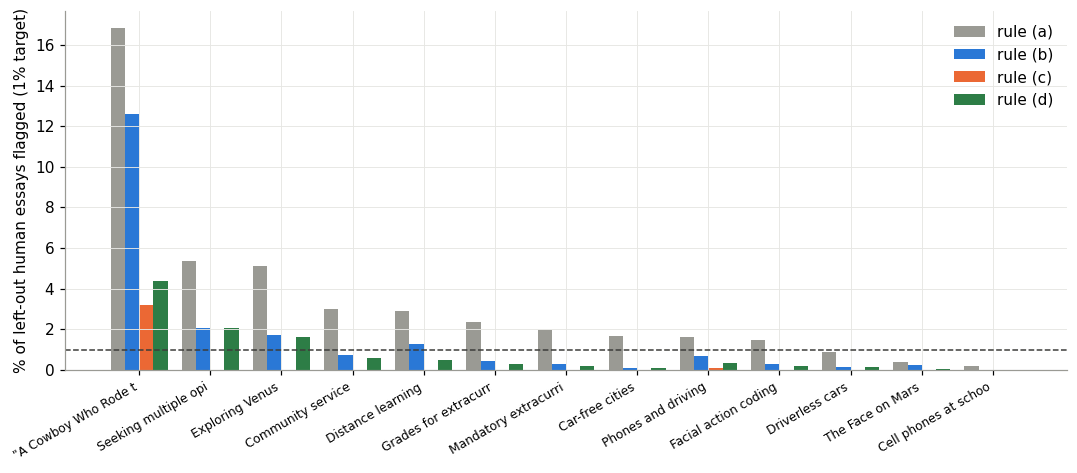

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.4))
order = tab.sort_values('a', ascending=False).index
x = np.arange(len(order)); w = 0.2
for j, (r, c) in enumerate(zip(RULES, (GREY, HUMAN, AI, GREEN))):
    ax.bar(x + (j - 1.5) * w, tab.loc[order, r], w, label=f'rule ({r})', color=c)
ax.axhline(1, color='#3d3d3a', linestyle='--', linewidth=1)
ax.set_xticks(x); ax.set_xticklabels([p[:20] for p in order], rotation=30, ha='right', fontsize=8)
ax.set_ylabel('% of left-out human essays flagged (1% target)'); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig('../images/18_rules_by_topic.png', dpi=150, bbox_inches='tight'); plt.show()

## 10 · The cannot-tell band with the chosen rule (section 6)

In [7]:
band = band_report(topics_A, CHOSEN, 0.01, 0.05, n_boot=N_BOOT, seed=SEED)
band.round(2).to_csv('../results/18_band_chosen_rule.csv')
print(f'rule ({CHOSEN}): flag if p <= tau(1%), cannot tell up to tau(5%); leave-one-topic-out over 13 topics, variant A')
band.round(2)

rule (b): flag if p <= tau(1%), cannot tell up to tau(5%); leave-one-topic-out over 13 topics, variant A


,estimate,lo,hi
human flagged %,1.58,1.09,1.79
human in band %,4.77,4.24,5.38
human not flagged %,93.65,93.35,94.44
AI flagged %,98.97,98.23,99.37
AI in band %,0.71,0.37,1.39
AI missed %,0.33,0.18,0.52
topics over target (flagged),30.77,15.38,46.15


In [8]:
sens = {}
for lo_t, hi_t in [(0.005, 0.05), (0.01, 0.10)]:
    sens[f'{lo_t:.1%} to {hi_t:.0%}'] = band_report(topics_A, CHOSEN, lo_t, hi_t, n_boot=200, seed=SEED)['estimate']
pd.DataFrame(sens).round(2)

,0.5% to 5%,1.0% to 10%
human flagged %,0.69,1.58
human in band %,5.67,9.75
human not flagged %,93.65,88.66
AI flagged %,98.45,98.97
AI in band %,1.22,0.83
AI missed %,0.33,0.20
topics over target (flagged),30.77,30.77


## 11 · The thresholds for Phase 5 (all 13 topics, none left out)

In [9]:
all_ph = [p[0] for p in _p_arrays(topics_A)]
final = pd.DataFrame({f'{t:.1%}': {r: set_tau(r, all_ph, t) for r in RULES} for t in (0.005, 0.01, 0.05)})
final.index.name = 'rule'
final.round(5).to_csv('../results/18_final_thresholds_p_scale.csv')
print(f'tau on the p scale from all 13 topics (variant A). The chosen rule is ({CHOSEN}).')
final.round(5)

tau on the p scale from all 13 topics (variant A). The chosen rule is (b).


,0.5%,1.0%,5.0%
rule,,,
a,0.00500,0.01000,0.05000
b,0.00186,0.00300,0.01794
c,0.00046,0.00046,0.00278
d,0.00047,0.00189,0.00946


## Verdict

*(Written after the code cells above were run. The rules, statistics, choice rule and band edges in sections 1-7 are as committed before the run, commit 978818c.)*

**1. The status quo does not hold on new topics.** With rule (a), a "1%" threshold set on pooled val essays, leaving one topic out of 13 gives a mean false-flag rate of **3.37% [2.86, 3.96]**, a worst topic at **16.84%**, and **77% of topics over the 1% target** (variant A models). Rule (a) catches 99.60% of AI essays [99.30, 99.75].

**2. By the pre-declared choice rule, rule (b), the pooled leave-one-prompt-out threshold, is chosen.** Qualifying rules (mean AI caught within 1.0 point of rule (a)): (a) and (b). Rule (b) has the smaller share of topics over target.

| rule (1% target) | mean false flags % | worst topic % | topics over target % | mean AI caught % | qualifies |
|---|---|---|---|---|---|
| (a) pooled val | 3.37 [2.86, 3.96] | 16.84 [12.61, 22.74] | 76.9 [61.5, 84.6] | 99.60 [99.30, 99.75] | (baseline) |
| **(b) pooled LOPO** | **1.58 [1.09, 1.79]** | 12.61 [3.64, 15.60] | **30.8 [15.4, 46.2]** | 98.97 [98.23, 99.37] | **yes, chosen** |
| (c) worst topic | 0.25 [0.08, 0.70] | 3.21 [1.03, 8.09] | 7.7 [7.7, 7.7] | **15.20 [7.53, 98.12]** | no |
| (d) topic quantile | 0.81 [0.50, 1.67] | 4.37 [1.75, 13.99] | 23.1 [23.1, 23.1] | 98.59 [82.96, 99.21] | **no, by 0.01 point** |

- **Rule (b) halves the false flags** (3.37% to 1.58% mean) at the cost of 0.63 points of AI caught. At the 0.5% target: mean 0.69% [0.53, 1.27] and AI caught 98.45%.
- **Rule (c) is unusable.** The single hardest topic (Cowboy, under variant A) forces the threshold to the smallest p-value, so almost nothing is flagged (AI caught 15%).
- **Rule (d) is a near-miss and worth a look.** It misses the pre-declared constraint by 0.01 point (98.59% against a required 98.60%), so the rule rejects it. On everything else it is better than (b): mean false flags 0.81% against 1.58%, worst topic 4.37% against 12.61%, topics over target 23% against 31%; it catches 0.4 points fewer AI essays. I followed the rule, but the call between (b) and (d) is a judgment you may reasonably make differently. Its AI-caught interval is wide (lower end 83%) because the 20th-percentile threshold is unstable when a topic like Cowboy is among those setting it.
- **A threshold cannot fix a model that mis-scores a topic.** Even under rule (b), Cowboy is at 12.61% false flags and 31% of topics are above 1%: the remaining topics over target are Cowboy, Seeking multiple opinions (2.06%) and Exploring Venus (1.72%) and the like.

**3. The cannot-tell band (rule (b); flag at p <= tau(1%), cannot tell up to tau(5%)).** Leave-one-topic-out, 13 topics, variant A:

| zone | humans | AI essays |
|---|---|---|
| flagged | 1.58% [1.09, 1.79] | 98.97% [98.23, 99.37] |
| cannot tell | **4.77% [4.24, 5.38]** | 0.71% [0.37, 1.39] |
| not flagged | 93.65% [93.35, 94.44] | 0.33% [0.18, 0.52] |

About 1 in 21 human essays would be reported as "cannot tell" instead of being accused or cleared, against about 1 in 140 AI essays: the band absorbs mostly humans. Outside the band, humans flagged are 1.58% and AI caught 98.97%. Sensitivity (exploratory): edges 0.5% to 5% give 0.69% humans flagged, 5.67% in the band, AI flagged 98.45%; edges 1% to 10% give 9.75% of humans in the band.

**4. Thresholds for Phase 5, on the p scale, from all 13 topics (no topic left out):** rule (b): tau(0.5%) = 0.00186, tau(1%) = 0.00300, tau(5%) = 0.01794 (`results/18_final_thresholds_p_scale.csv`). In words: to meet a 1% target on new topics, flag only essays that score above all but **0.3%** of the val humans, not above all but 1%.

**5. Context, not used for the choice: the same analysis on the original recipe.** With the original recipe's 13 folds, rule (a) gives mean 2.71% / worst 5.24% / 77% of topics over target; rule (b) 1.09% / 3.22% / 46%; rule (d) 0.58% [0.44, 0.89] / 1.74% / 23% with mean AI caught 98.78% [97.89, 99.15] (**it qualifies there**, so the declared choice rule would select (d) for the original recipe). Original recipe with rule (d) beats variant A with rule (b) on mean false flags, worst topic and share of topics over target, and catches about the same share of AI essays. That is exploratory, but it bears on the recipe decision below.

**6. The recipe question (new evidence from the 13 folds, `17b_augment_results.ipynb` section 4).** On all 13 prompts, variant A is **not** better than the original recipe: mean false-flag change **+0.57 points [+0.19, +1.16]**, because of Cowboy (4.30% to 17.42%); the six folds added after Phase 3 average +2.24 [+1.71, +3.18]. The seven pre-registered folds were chosen from the extremes of the baseline, which probably flatters any change; this is an after-the-fact extension, flagged as such, and it does not change the pre-registered Phase 3 decision, but it means the choice of recipe for Phase 5 should be revisited.

**Limits.** Single-seed leave-one-prompt-out models, 13 topics; intervals include the val-human, left-out-human and AI-essay resampling but not training-seed variation; the threshold is judged on the same 13 topics it is finally computed from (leave-one-topic-out protects each estimate, but the final tau uses all 13). The single-seed to three-seed-ensemble carry-over (section 7) is an assumption, untested until the end of Phase 5. The held-out prompts and generators were not scored.

## Key takeaways

- **Use p-values, not logits, as the threshold scale**: a 1% logit threshold belongs to one trained model (seeds: +4.57, +3.58, -0.13); a threshold on the val-human tail probability is comparable across seeds, folds and recipes.
- **Do not set the threshold on pooled validation essays alone.** Leave-one-topic-out, 77% of topics exceed the 1% target and the mean is 3.4%.
- **Rule (b) (pooled left-out-prompt humans) is the pre-declared choice**: mean false flags 1.58%, 31% of topics over target, 0.6 points of AI caught lost. Rule (d) is a near-miss (0.01 point outside the constraint) with a lower worst topic; the decision between them is open for you.
- **The cannot-tell band between rule (b)'s 1% and 5% thresholds puts about 4.8% of human essays and 0.7% of AI essays in "cannot tell"**, and leaves 1.58% of humans flagged.
- **A threshold cannot rescue a model that fails on a topic** (Cowboy under variant A: 12.6% even with rule (b)). The recipe question (section 6) matters more than the rule.
- **Reusable:** `src/conformal.py`, `results/18_*.csv` (comparison, by topic, band, final p-scale thresholds), `images/18_rules_by_topic.png`.